In [1]:
!pip install tensorflow tensorflow.keras
!pip install numpy
!pip install scipy
!pip install pandas
!pip install matplotlib
!pip install scikit-learn


Coercion summary (new NaNs introduced by coercion):
  shallow_depth_s: +0 NaNs
  Deep_depth_s: +0 NaNs
  river_discharge: +0 NaNs
  shallow_depth_t: +0 NaNs
  Deep_depth_t: +0 NaNs
  chlorophyll_depth: +0 NaNs
Examples of original values coerced to NaN (up to 5 examples per column):
  shallow_depth_s: []
  Deep_depth_s: []
  river_discharge: []
  shallow_depth_t: []
  Deep_depth_t: []
  chlorophyll_depth: []
Dropped 27 rows with NaNs in required columns (remaining 575 rows).
Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):
     shallow_depth_s  Deep_depth_s  river_discharge  shallow_depth_t  \
170            0.100           NaN           4600.0            0.724   
520            0.992         2.373              NaN            5.343   
521            0.185         8.361              NaN            4.972   
522            0.031         7.100              NaN            0.031   
523            0.030        11.426              NaN            0.030   

     Deep_depth_t  

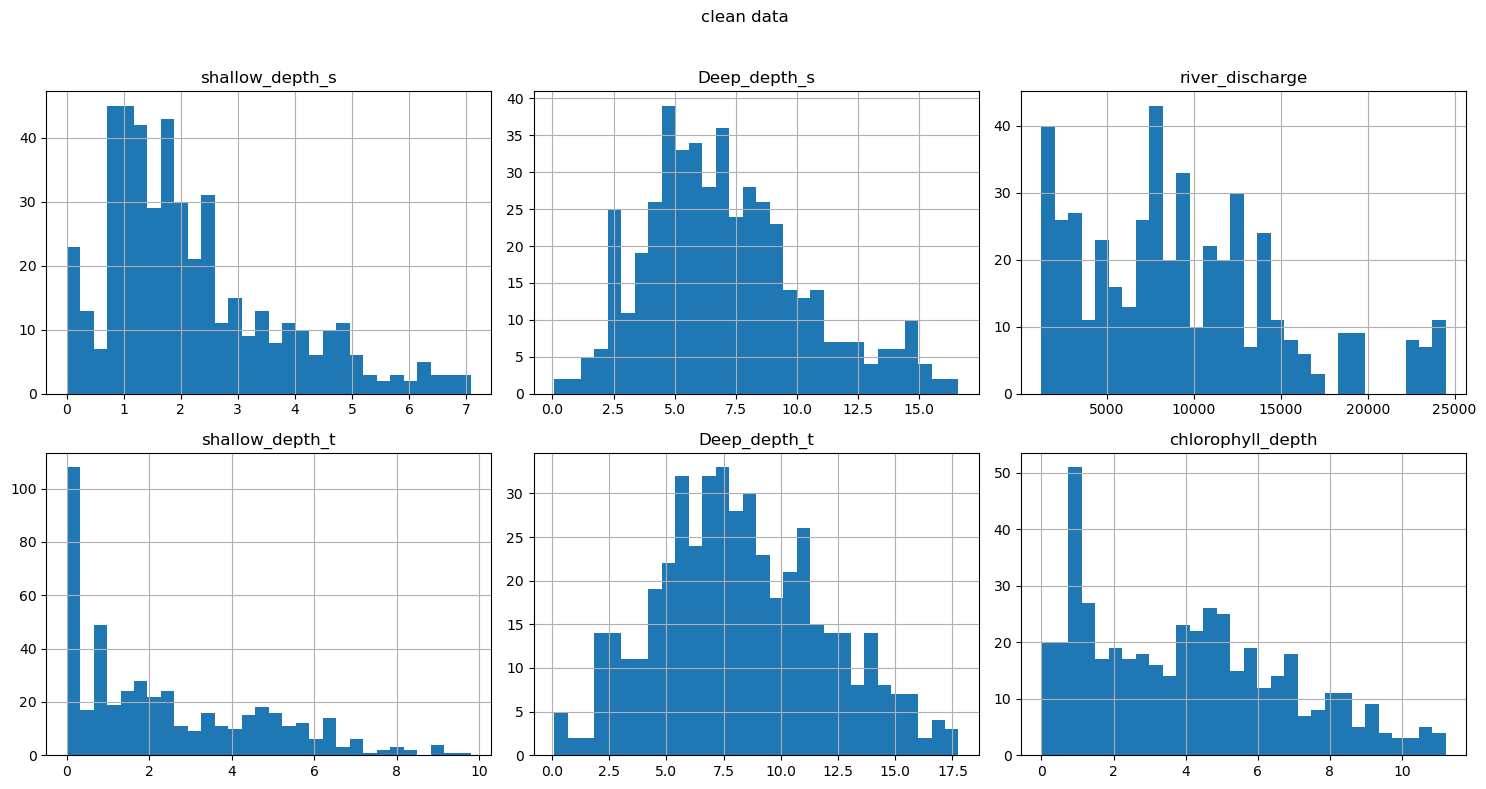

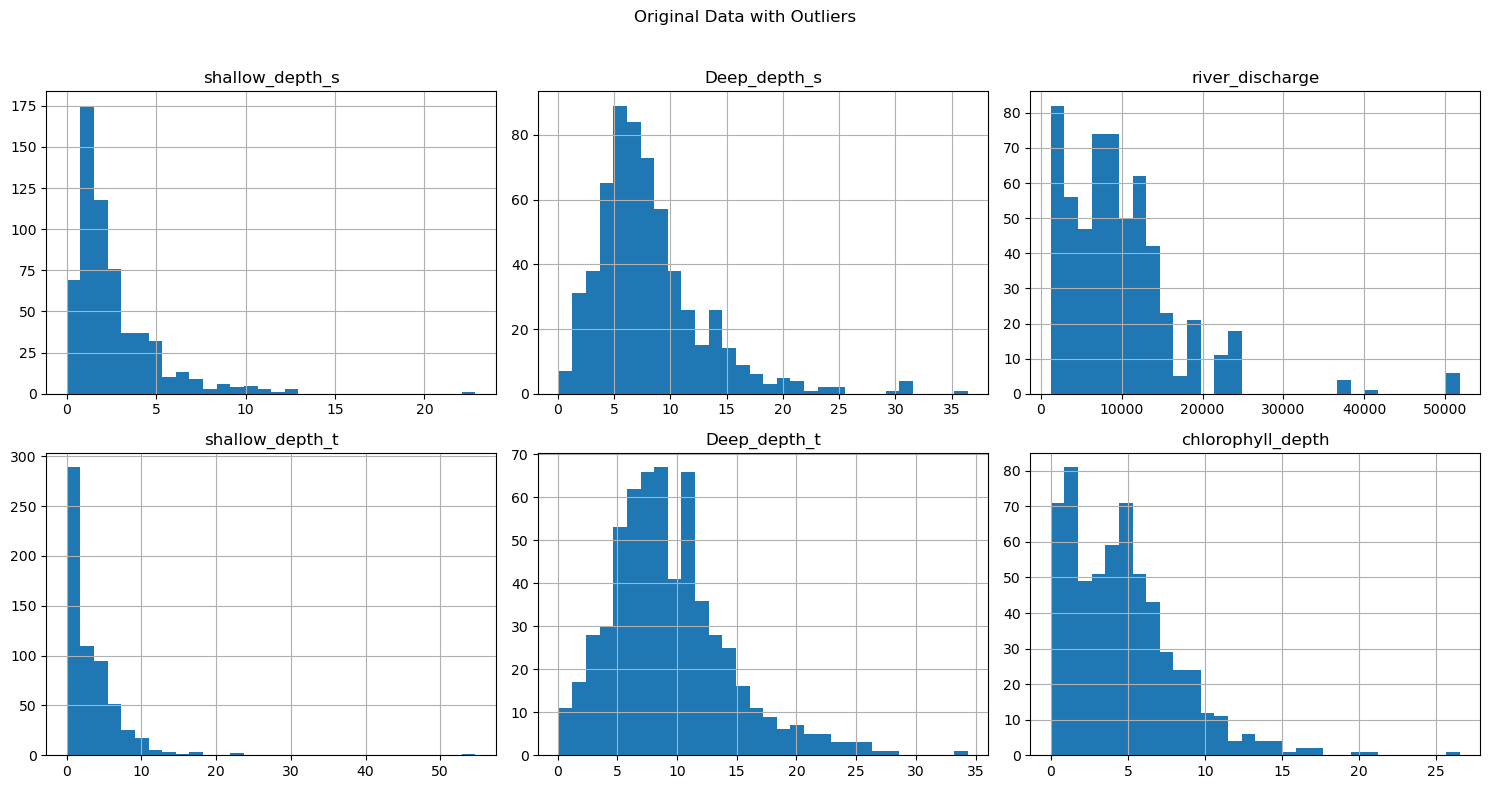

In [1]:

# 2. Load and Prepare Your Data
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Load data
data = pd.read_csv('Raw data chlorocline.csv', encoding='latin-1') # Try 'latin-1' encoding

# Feature and target columns (ensure these match your CSV headers)
feature_cols = ['shallow_depth_s', 'Deep_depth_s','river_discharge','shallow_depth_t', 'Deep_depth_t']
target_col = 'chlorophyll_depth'


def remove_outliers(df):
    """
    Removes rows containing outliers in the specified columns using the Z-score method.
    """
    df_cleaned = df.copy()
    cols_to_check = feature_cols + [target_col]
    present_cols = [c for c in cols_to_check if c in df_cleaned.columns]
    missing_cols = [c for c in cols_to_check if c not in df_cleaned.columns]
    if missing_cols:
        print(f"Warning: Column(s) not found in the DataFrame and will be skipped: {missing_cols}")

    # Ensure we don't try to z-score constant or empty columns
    for col in present_cols:
        # coerce object columns to numeric where possible
        if df_cleaned[col].dtype == object:
            df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')
        if df_cleaned[col].dropna().nunique() <= 1:
            continue
        # compute zscore safely
        try:
            z = stats.zscore(df_cleaned[col].astype(float))
        except Exception:
            continue
        outlier_mask = np.abs(z) > 2  # adjust threshold if desired
        df_cleaned = df_cleaned[~outlier_mask]

    return df_cleaned


def coerce_and_clean_numeric(df, cols, target_col):
    """Coerce listed columns to numeric, replace infs, drop rows with NaNs, and provide diagnostics.

    Returns the cleaned DataFrame (rows kept). Also saves dropped rows to 'dropped_rows_inspection.csv'.
    """
    df2 = df.copy()
    converted = {}
    coercion_examples = {}

    for c in cols + [target_col]:
        if c in df2.columns:
            before_na = df2[c].isna().sum()
            # attempt coercion and capture examples of values that fail
            coerced = pd.to_numeric(df2[c], errors='coerce')
            coerced_mask = df2[c].notna() & coerced.isna()
            coercion_examples[c] = df2.loc[coerced_mask, c].head(5).tolist()
            df2[c] = coerced
            after_na = df2[c].isna().sum()
            converted[c] = after_na - before_na

    # Replace inf values with NaN
    df2 = df2.replace([np.inf, -np.inf], np.nan)

    print("Coercion summary (new NaNs introduced by coercion):")
    for k, v in converted.items():
        print(f"  {k}: +{v} NaNs")

    print("Examples of original values coerced to NaN (up to 5 examples per column):")
    for k, v in coercion_examples.items():
        print(f"  {k}: {v}")

    present_cols = [c for c in cols + [target_col] if c in df2.columns]
    before = df2.shape[0]

    # identify rows that will be dropped and keep a copy for diagnostics
    dropped_rows = df2[df2[present_cols].isnull().any(axis=1)].copy() if present_cols else df2.iloc[0:0].copy()
    df2_kept = df2.dropna(subset=present_cols) if present_cols else df2.copy()
    after = df2_kept.shape[0]

    print(f"Dropped {before - after} rows with NaNs in required columns (remaining {after} rows).")

    if not dropped_rows.empty:
        # summarize drop reasons per-row
        def reasons(row):
            return [col for col in present_cols if pd.isna(row[col])]
        dropped_rows['drop_reasons'] = dropped_rows.apply(reasons, axis=1)
        # save dropped rows for inspection
        try:
            dropped_rows.to_csv('dropped_rows_inspection.csv', index=False)
            print("Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):")
        except Exception as e:
            print("Failed to save dropped_rows_inspection.csv:", e)
        display_cols = [c for c in present_cols if c in dropped_rows.columns]
        print(dropped_rows.head()[display_cols + ['drop_reasons']])

    return df2_kept


# Apply cleaning and outlier removal
if 'data' in locals():
    data_numeric = coerce_and_clean_numeric(data, feature_cols, target_col)
    data_cleaned = remove_outliers(data_numeric)
    # Save cleaned data for inspection
    try:
        data_cleaned.to_csv('data_cleaned.csv', index=False)
        print("Saved cleaned data to 'data_cleaned.csv'")
    except Exception as e:
        print("Failed to save data_cleaned.csv:", e)

    print("Original DataFrame shape:", data.shape)
    print("DataFrame shape after coercion+outlier removal:", data_cleaned.shape)
else:
    print("Please load your DataFrame into a variable named 'data' before running this code.")


def plot_histograms(data, feature_cols, target_col, title):
    """
    Plots histograms for the specified feature columns and target column.

    Args:
        data (pd.DataFrame): The input DataFrame.
        feature_cols (list): List of feature column names.
        target_col (str): The target column name.
    """
    columns_to_plot = [c for c in feature_cols + [target_col] if c in data.columns]
    if not columns_to_plot:
        print("No columns available to plot.")
        return
    data[columns_to_plot].hist(bins=30, figsize=(15, 8), layout=(2, 3))
    plt.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# If data_cleaned exists, plot histograms
if 'data_cleaned' in locals():
    plot_histograms(data_cleaned, feature_cols, target_col, 'clean data')
if 'data' in locals():
    plot_histograms(data, feature_cols, target_col, "Original Data with Outliers")


2025-09-30 08:54:42.784930: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1759247682.801038  111741 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1759247682.806668  111741 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-09-30 08:54:42.825059: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-09-30 08:54:44.181929: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_UNKNOWN: unknown error
2025-09-30 08:54:44.181953: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:137] retrieving CUDA diagnostic information for host: llenoyann
2025-09-30 08:54:44.181975: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:144] hostname: llenoyann
2025-09-30 08:54:44.182146: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:168] libcuda reported version is: 550.163.1
2025-09-30 08:54:44.182166: I external/local_

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 14.9842 - val_loss: 7.5741
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6493 - val_loss: 7.5741
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5640 - val_loss: 7.6016
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5340 - val_loss: 7.6119
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5751 - val_loss: 7.6200
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1772 - val_loss: 7.6569
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7710 - val_loss: 7.6272
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7776 - val_loss: 7.5773
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5636 - val_loss: 7.6080
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8450 - val_loss: 7.6059
tanh_adam_10=>Activation: tanh, Optimizer: adam, Epochs: 10, Test MSE: 8.52387523651123


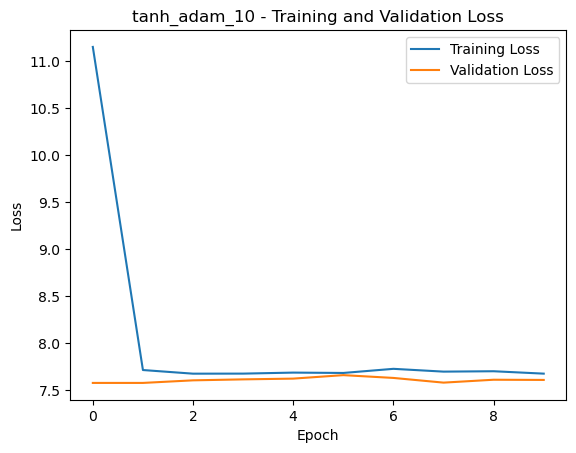

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 13.2132 - val_loss: 7.6618
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3972 - val_loss: 7.5736
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5380 - val_loss: 7.6226
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9633 - val_loss: 7.5829
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8158 - val_loss: 7.7675
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7260 - val_loss: 7.5928
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9113 - val_loss: 7.5990
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2180 - val_loss: 7.5730
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.6889 - val_loss: 7.5897
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5014 - val_loss: 7.5912
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2609 - val_loss: 7.5820
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4103 - val_loss: 7.643

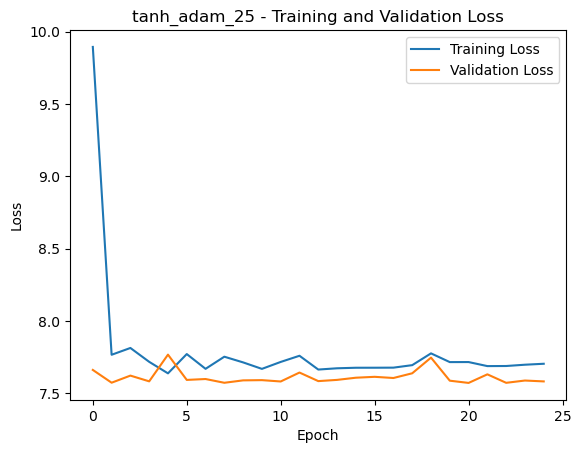

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 12.4112 - val_loss: 7.5740
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9067 - val_loss: 7.6944
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0092 - val_loss: 7.6080
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8464 - val_loss: 7.5864
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2902 - val_loss: 7.6635
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3394 - val_loss: 7.5720
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7579 - val_loss: 7.5722
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5471 - val_loss: 7.5794
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2542 - val_loss: 7.5951
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.7359 - val_loss: 7.6301
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8705 - val_loss: 7.5937
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8973 - val_loss: 7.624

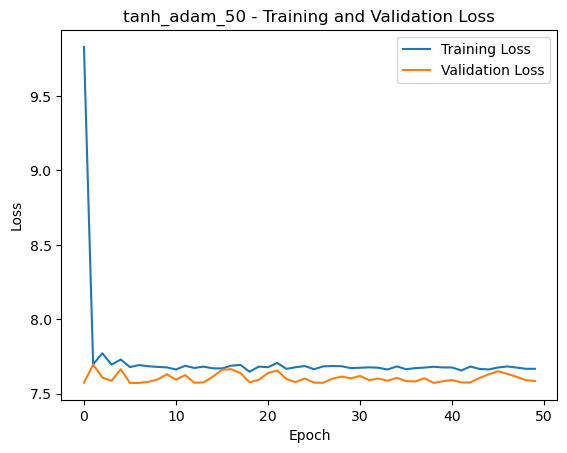

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 11.1036 - val_loss: 7.5845
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.6960 - val_loss: 7.5806
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8735 - val_loss: 7.5720
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2443 - val_loss: 7.7473
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2025 - val_loss: 7.5724
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3689 - val_loss: 7.5896
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5614 - val_loss: 7.7553
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1559 - val_loss: 7.5794
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4749 - val_loss: 7.5761
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5494 - val_loss: 7.6657
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4612 - val_loss: 7.5934
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1790 - val_

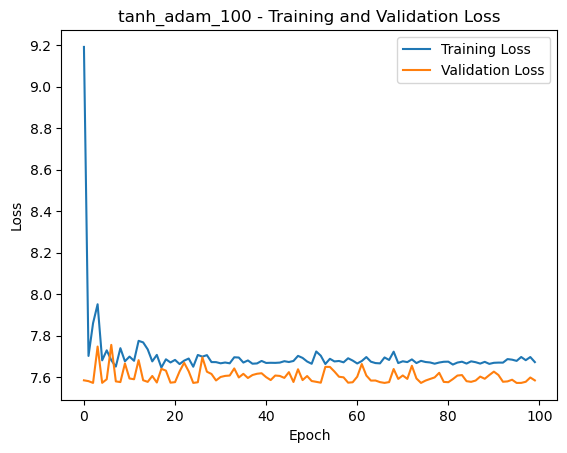

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 10.3652 - val_loss: 7.6485
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.2089 - val_loss: 7.7225
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8639 - val_loss: 7.6247
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7120 - val_loss: 7.5760
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9577 - val_loss: 7.5896
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6575 - val_loss: 7.5727
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5618 - val_loss: 7.5721
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2188 - val_loss: 7.5786
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9823 - val_loss: 7.6532
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6205 - val_loss: 7.6247
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5781 - val_loss: 7.5848
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0456 - val_

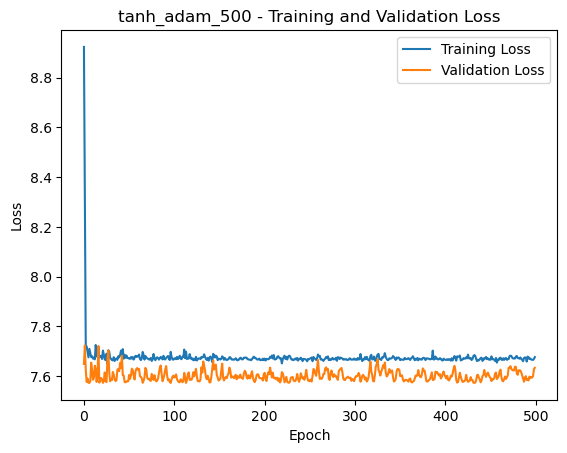

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 11.8230 - val_loss: 7.6189
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5246 - val_loss: 7.7620
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0428 - val_loss: 7.5744
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7844 - val_loss: 7.5748
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0684 - val_loss: 7.5730
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9098 - val_loss: 7.6685
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1939 - val_loss: 7.6030
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6699 - val_loss: 7.5768
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0102 - val_loss: 7.5791
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.9969 - val_loss: 7.6398
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.6420 - val_loss: 7.5762
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.

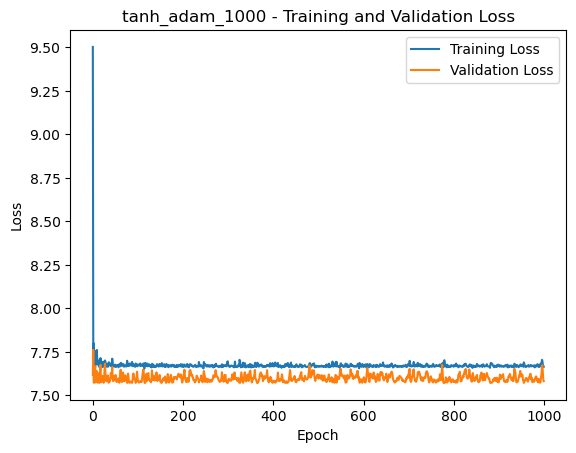

Epoch 1/10
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - loss: 15.3881

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 10.0512 - val_loss: 7.7143
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9279 - val_loss: 7.5730
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6852 - val_loss: 7.6509
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7795 - val_loss: 7.6048
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5709 - val_loss: 7.6990
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5686 - val_loss: 7.6818
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5222 - val_loss: 8.9426
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2212 - val_loss: 8.1938
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7800 - val_loss: 8.0294
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7982 - val_loss: 8.0197
tanh_sgd_10=>Activation: tanh, Optimizer: sgd, Epochs: 10, Test MSE: 8.37826156616211


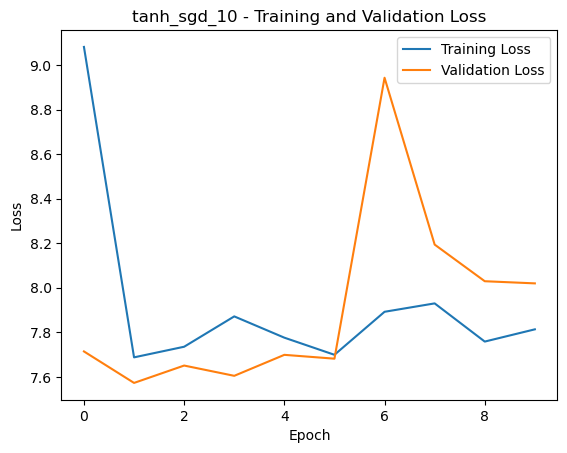

Epoch 1/25
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - loss: 15.4229

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 10.2440 - val_loss: 9.0205
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.0184 - val_loss: 8.2476
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1740 - val_loss: 7.7037
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5351 - val_loss: 11.6512
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.1451 - val_loss: 7.5996
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0431 - val_loss: 8.3159
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8844 - val_loss: 7.5770
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1410 - val_loss: 9.8129
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9416 - val_loss: 7.6962
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2239 - val_loss: 7.5993
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4246 - val_loss: 7.6550
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7018 - val_loss: 8.89

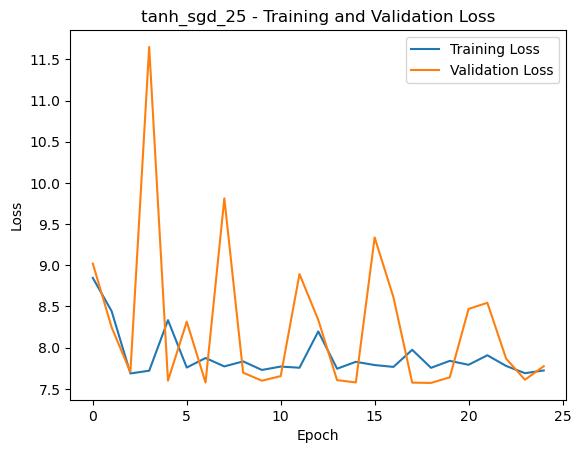

Epoch 1/50
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 153ms/step - loss: 26.2860

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 12.9266 - val_loss: 8.4077
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6998 - val_loss: 8.1192
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6564 - val_loss: 7.7185
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0416 - val_loss: 9.3019
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6402 - val_loss: 7.5915
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6964 - val_loss: 7.5937
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7122 - val_loss: 7.7296
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8336 - val_loss: 7.6922
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1757 - val_loss: 7.5775
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7732 - val_loss: 8.5820
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6804 - val_loss: 7.9482
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2731 - val_loss: 7.654

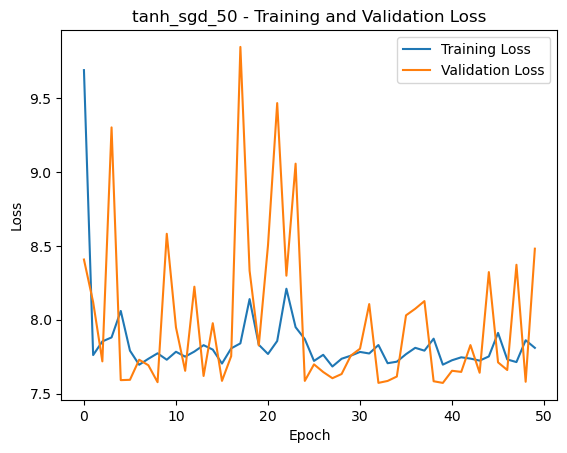

Epoch 1/100
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 152ms/step - loss: 16.5512

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 10.4323 - val_loss: 8.2887
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.2500 - val_loss: 7.9496
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1627 - val_loss: 7.6698
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2822 - val_loss: 7.9376
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8545 - val_loss: 8.0292
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0370 - val_loss: 8.2291
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7637 - val_loss: 7.5757
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5165 - val_loss: 7.5899
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1787 - val_loss: 7.8574
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2828 - val_loss: 7.6370
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2322 - val_loss: 9.2163
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4157 - val_

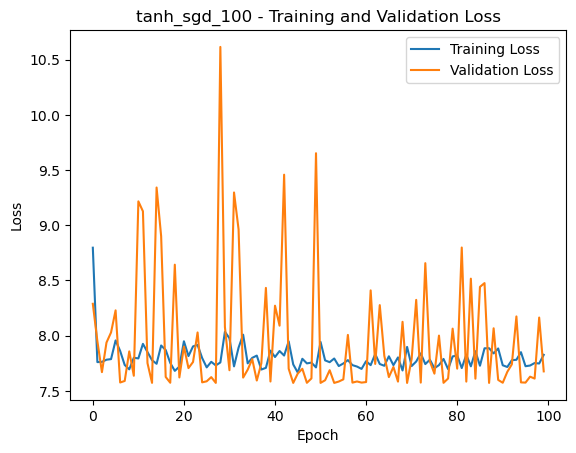

Epoch 1/500
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 150ms/step - loss: 30.6853

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 13.8818 - val_loss: 7.6661
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3149 - val_loss: 9.3304
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3752 - val_loss: 7.7189
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3661 - val_loss: 7.9629
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0039 - val_loss: 8.7080
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5391 - val_loss: 8.5813
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.5159 - val_loss: 7.6426
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9422 - val_loss: 8.0608
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0505 - val_loss: 8.3796
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0593 - val_loss: 7.6011
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.9562 - val_loss: 8.0288
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0784 - val_

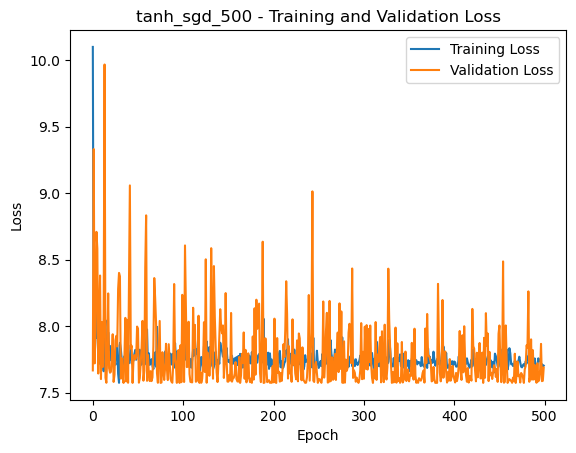

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 12.7434 - val_loss: 7.8499
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0325 - val_loss: 7.6624
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8136 - val_loss: 7.9120
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5782 - val_loss: 8.3991
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2057 - val_loss: 7.5795
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0662 - val_loss: 7.6865
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4060 - val_loss: 8.2107
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5823 - val_loss: 7.5979
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6031 - val_loss: 7.7723
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.9812 - val_loss: 7.5935
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2744 - val_loss: 7.5725
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.

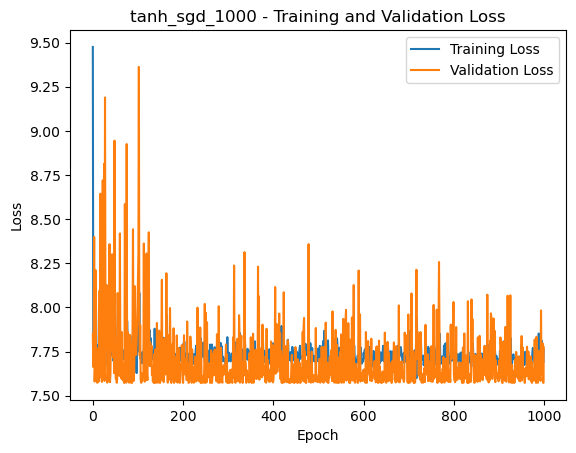

Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 11.2582 - val_loss: 7.5749
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7124 - val_loss: 7.5732
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8004 - val_loss: 7.9798
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0795 - val_loss: 7.5722
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3128 - val_loss: 7.5896
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5548 - val_loss: 7.5727
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4421 - val_loss: 7.9375
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7041 - val_loss: 7.7308
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8594 - val_loss: 7.5891
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9192 - val_loss: 7.7529
tanh_rmsprop_10=>Activation: tanh, Optimizer: rmsprop, Epochs: 10, Test MSE: 8.392696380615234


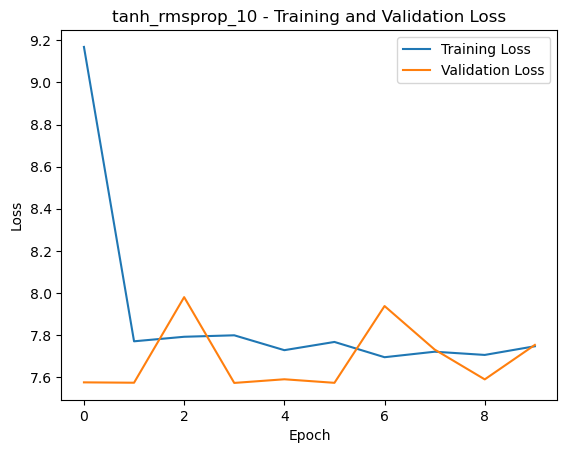

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 11.2234 - val_loss: 7.6724
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8173 - val_loss: 8.5428
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9839 - val_loss: 7.8602
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3227 - val_loss: 8.0159
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7951 - val_loss: 7.5925
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0398 - val_loss: 7.5747
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7004 - val_loss: 7.8285
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6469 - val_loss: 7.5920
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1650 - val_loss: 7.8534
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5361 - val_loss: 7.6278
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5164 - val_loss: 7.5784
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3845 - val_loss: 8.230

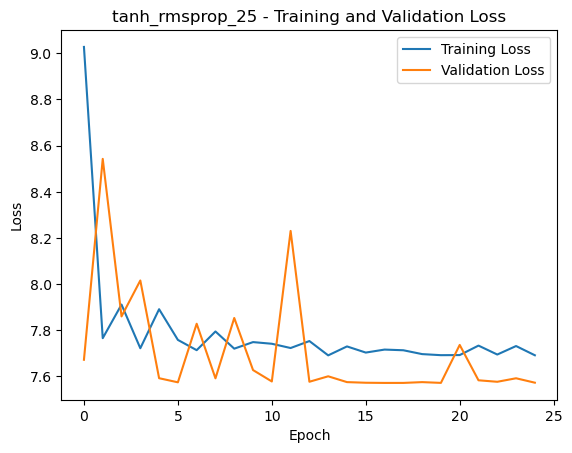

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 10.1487 - val_loss: 7.5826
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1487 - val_loss: 7.5721
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0739 - val_loss: 7.5943
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6708 - val_loss: 7.6062
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4800 - val_loss: 8.2650
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5884 - val_loss: 7.8775
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6886 - val_loss: 7.5920
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4878 - val_loss: 7.5850
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0354 - val_loss: 8.1566
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6471 - val_loss: 7.5994
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8493 - val_loss: 7.5773
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6917 - val_loss: 7.598

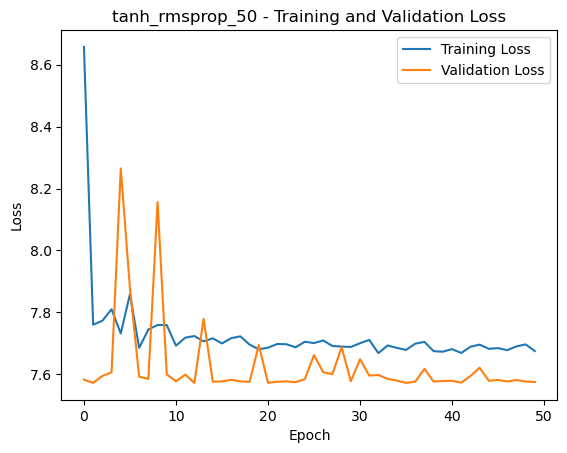

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 11.7745 - val_loss: 7.5747
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2592 - val_loss: 7.6854
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9194 - val_loss: 8.7114
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5599 - val_loss: 7.6516
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6236 - val_loss: 7.5745
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8855 - val_loss: 7.6072
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7939 - val_loss: 8.1499
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2485 - val_loss: 7.7151
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9935 - val_loss: 7.8376
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4631 - val_loss: 7.5872
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0912 - val_loss: 7.6241
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9643 - val_

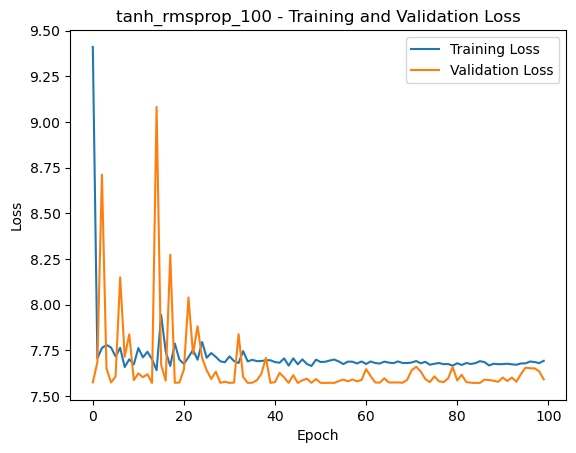

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 10.3976 - val_loss: 9.1306
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1994 - val_loss: 7.6917
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6393 - val_loss: 7.9163
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5208 - val_loss: 7.7377
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5079 - val_loss: 7.7550
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0150 - val_loss: 7.6938
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6472 - val_loss: 7.5721
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8441 - val_loss: 7.6405
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8286 - val_loss: 7.7323
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7177 - val_loss: 7.6372
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5125 - val_loss: 7.5952
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4670 - val_

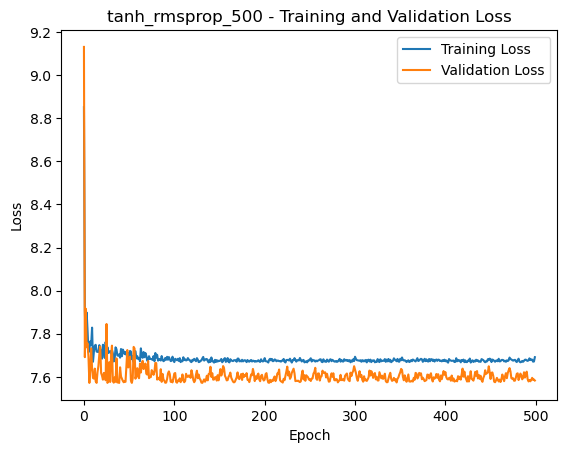

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 13.8113 - val_loss: 10.5919
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3500 - val_loss: 7.5898
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8654 - val_loss: 7.6287
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6468 - val_loss: 7.5870
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4680 - val_loss: 7.5836
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4217 - val_loss: 8.5832
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4195 - val_loss: 7.6786
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9965 - val_loss: 7.6783
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.8326 - val_loss: 7.5720
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2379 - val_loss: 7.7493
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3515 - val_loss: 7.6807
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7

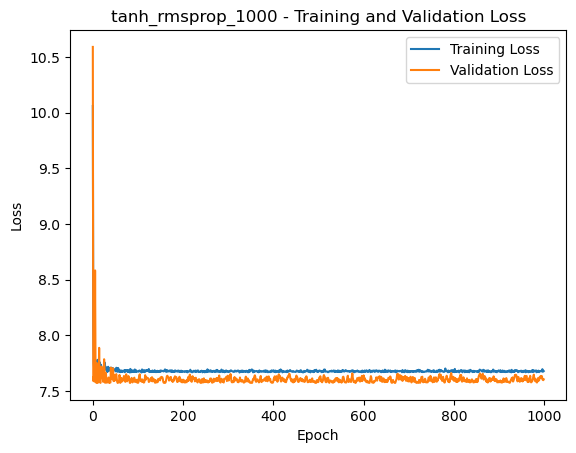

Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 24.6266 - val_loss: 19.4087
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 17.5097 - val_loss: 14.1844
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13.6986 - val_loss: 11.4032
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.5067 - val_loss: 9.9103
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.7408 - val_loss: 9.0406
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6159 - val_loss: 8.4569
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6217 - val_loss: 8.1507
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3846 - val_loss: 7.9726
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1366 - val_loss: 7.8507
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7816 - val_loss: 7.7666
sigmoid_adam_10=>Activation: sigmoid, Optimizer: adam, Epochs: 10, Test MSE: 8.388147354125977


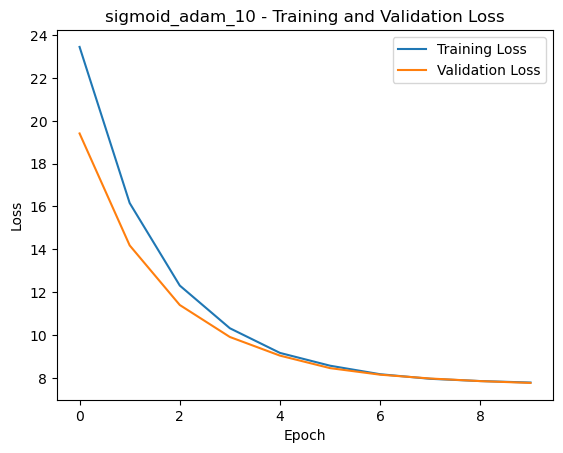

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 24.9858 - val_loss: 21.1548
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 17.1418 - val_loss: 15.9686
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13.9323 - val_loss: 13.1865
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 12.1441 - val_loss: 11.4944
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.8606 - val_loss: 10.4005
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.0531 - val_loss: 9.7061
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.8296 - val_loss: 9.1914
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4280 - val_loss: 8.8318
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1643 - val_loss: 8.5381
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.8425 - val_loss: 8.3364
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6673 - val_loss: 8.1802
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6609 - val_l

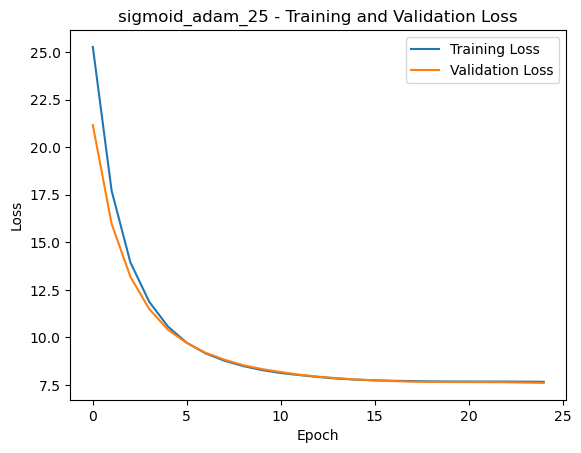

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 23.8983 - val_loss: 19.7320
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 18.0102 - val_loss: 14.5703
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 12.0809 - val_loss: 11.9750
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.5799 - val_loss: 10.3957
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.2647 - val_loss: 9.4785
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.1668 - val_loss: 8.8791
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2190 - val_loss: 8.5096
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5144 - val_loss: 8.2385
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9740 - val_loss: 8.0479
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6113 - val_loss: 7.9325
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2966 - val_loss: 7.8264
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0411 - val_los

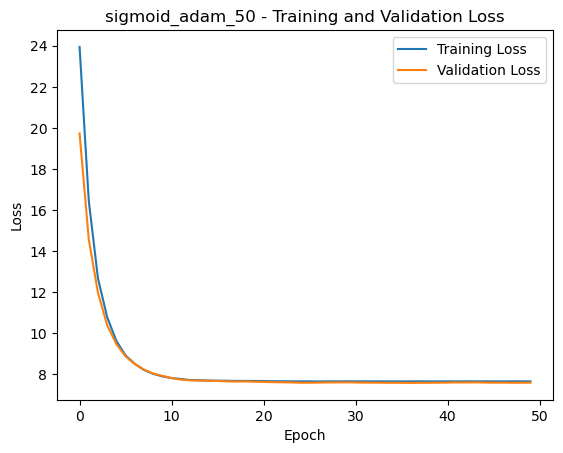

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 14.7572 - val_loss: 10.5994
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.1357 - val_loss: 8.4391
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1500 - val_loss: 7.7515
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9686 - val_loss: 7.6168
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0918 - val_loss: 7.5909
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3083 - val_loss: 7.5846
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5452 - val_loss: 7.5792
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7597 - val_loss: 7.5970
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0646 - val_loss: 7.6041
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.7605 - val_loss: 7.6281
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0173 - val_loss: 7.6163
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1237 - va

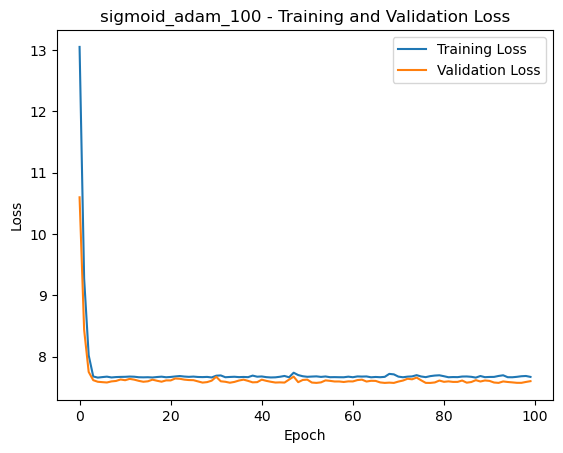

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 25.3376 - val_loss: 18.4816
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 16.6285 - val_loss: 12.6261
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.7694 - val_loss: 10.0382
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.5990 - val_loss: 8.8330
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0686 - val_loss: 8.3074
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8451 - val_loss: 8.0305
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4309 - val_loss: 7.8696
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7338 - val_loss: 7.7555
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2164 - val_loss: 7.6861
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.4732 - val_loss: 7.6521
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3878 - val_loss: 7.6360
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0929 -

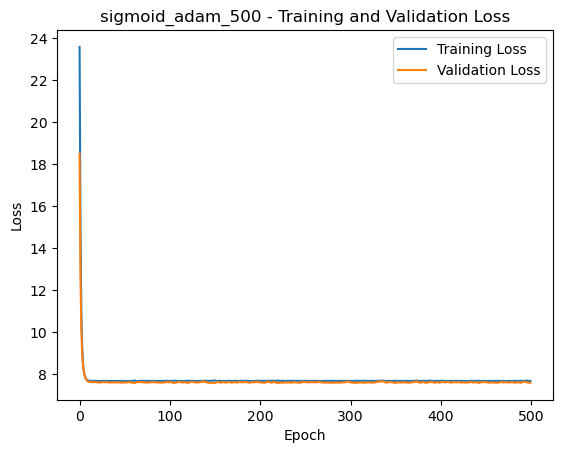

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 17.6370 - val_loss: 12.8484
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.8721 - val_loss: 9.8593
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.4043 - val_loss: 8.5700
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.8618 - val_loss: 7.9934
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6699 - val_loss: 7.8120
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2938 - val_loss: 7.6984
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5436 - val_loss: 7.6500
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.8167 - val_loss: 7.6192
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6231 - val_loss: 7.6044
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0332 - val_loss: 7.5842
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4687 - val_loss: 7.5766
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss:

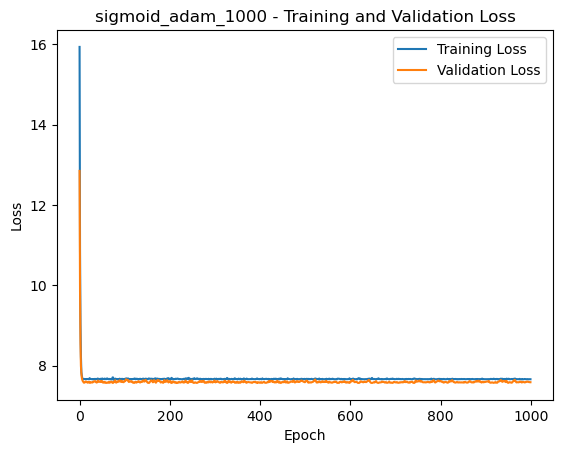

Epoch 1/10
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - loss: 29.1207

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 17.1105 - val_loss: 7.6489
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9487 - val_loss: 7.5905
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6804 - val_loss: 7.7030
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8783 - val_loss: 7.6322
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7039 - val_loss: 7.8281
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.9545 - val_loss: 7.5825
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0876 - val_loss: 7.6944
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5307 - val_loss: 7.6852
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0179 - val_loss: 7.6570
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5364 - val_loss: 7.5720
sigmoid_sgd_10=>Activation: sigmoid, Optimizer: sgd, Epochs: 10, Test MSE: 8.698112487792969


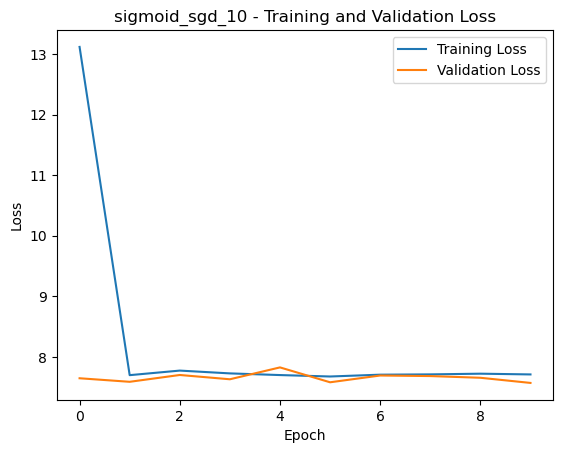

Epoch 1/25
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 152ms/step - loss: 28.2988

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 14.5277 - val_loss: 7.7913
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2875 - val_loss: 7.7070
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9961 - val_loss: 7.5889
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5966 - val_loss: 7.6827
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4833 - val_loss: 7.5723
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9858 - val_loss: 7.5960
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6495 - val_loss: 7.5990
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2618 - val_loss: 7.6799
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7050 - val_loss: 7.9781
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9515 - val_loss: 7.6285
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3861 - val_loss: 7.8057
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5228 - val_loss: 7.638

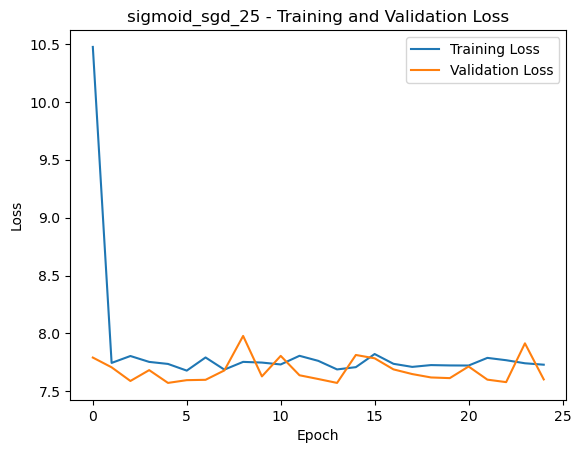

Epoch 1/50
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 150ms/step - loss: 26.7137

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 17.3593 - val_loss: 7.5889
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5535 - val_loss: 7.6901
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8471 - val_loss: 7.7110
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3725 - val_loss: 7.5728
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2262 - val_loss: 7.6334
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6736 - val_loss: 7.8001
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8015 - val_loss: 7.6880
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4342 - val_loss: 7.7290
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0826 - val_loss: 7.6996
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0437 - val_loss: 7.6016
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4002 - val_loss: 7.6023
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2026 - val_loss: 7.585

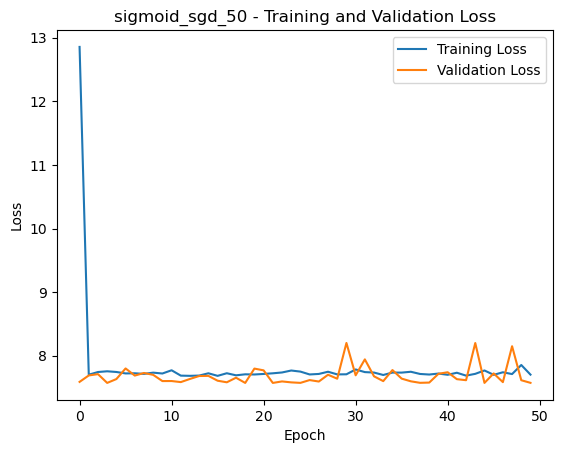

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 15.5810 - val_loss: 7.5720
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5591 - val_loss: 7.5722
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4057 - val_loss: 8.0563
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2678 - val_loss: 7.7074
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3794 - val_loss: 7.6004
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3881 - val_loss: 7.6048
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7350 - val_loss: 8.1785
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6144 - val_loss: 7.6828
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8188 - val_loss: 7.7785
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6985 - val_loss: 7.8189
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4797 - val_loss: 7.6807
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9648 - val_

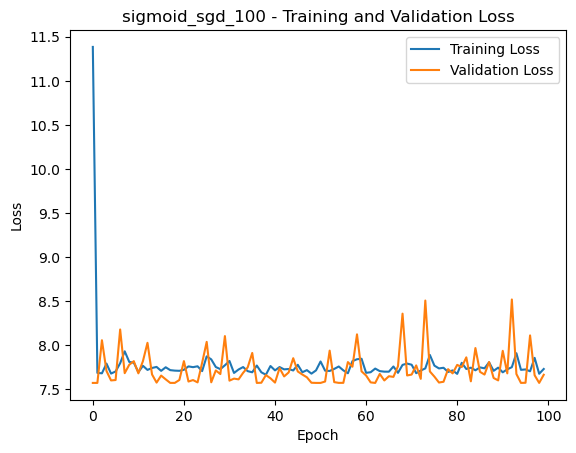

Epoch 1/500
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - loss: 21.8280

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 13.7861 - val_loss: 7.6235
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6843 - val_loss: 8.1261
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7847 - val_loss: 7.5757
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6433 - val_loss: 8.1780
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2248 - val_loss: 7.9337
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1529 - val_loss: 7.8579
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6317 - val_loss: 7.5747
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4257 - val_loss: 7.6201
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0609 - val_loss: 7.6029
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3751 - val_loss: 7.7384
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6121 - val_loss: 7.6262
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1713 - val_

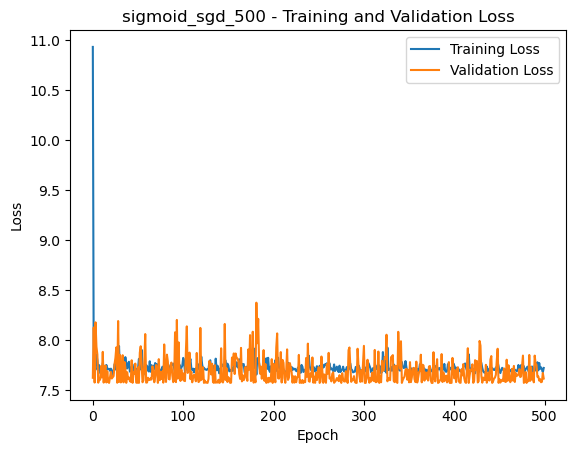

Epoch 1/1000
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 150ms/step - loss: 21.0428

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 14.5947 - val_loss: 8.2541
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4510 - val_loss: 7.6225
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4881 - val_loss: 8.2931
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3798 - val_loss: 7.8550
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1853 - val_loss: 7.5998
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8285 - val_loss: 7.6384
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2946 - val_loss: 7.7864
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3788 - val_loss: 7.5720
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0294 - val_loss: 7.6614
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7669 - val_loss: 7.5927
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8943 - val_loss: 7.6663
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.

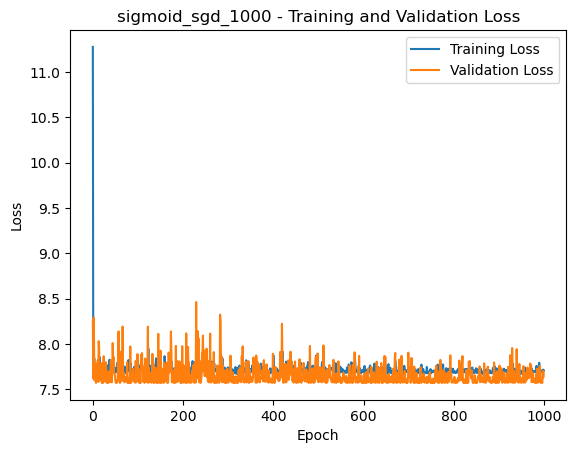

Epoch 1/10


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 18.2489 - val_loss: 12.1284
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.4777 - val_loss: 9.6338
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.8636 - val_loss: 8.8417
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.1990 - val_loss: 8.2036
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5568 - val_loss: 7.9634
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0873 - val_loss: 7.7987
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8661 - val_loss: 7.7030
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5726 - val_loss: 7.6808
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2055 - val_loss: 7.6390
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5044 - val_loss: 7.6103
sigmoid_rmsprop_10=>Activation: sigmoid, Optimizer: rmsprop, Epochs: 10, Test MSE: 8.51501178741455


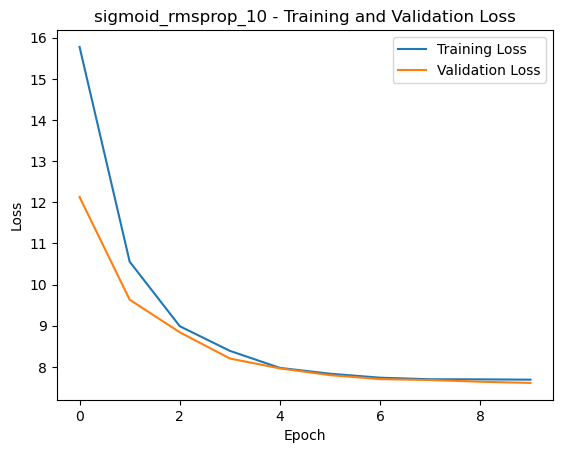

Epoch 1/25


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 18.5322 - val_loss: 12.2028
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.8262 - val_loss: 9.6894
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.4770 - val_loss: 8.4297
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4601 - val_loss: 8.0017
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6688 - val_loss: 7.6846
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9369 - val_loss: 7.7062
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0491 - val_loss: 7.6011
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2970 - val_loss: 7.6531
Epoch 9/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2930 - val_loss: 7.5824
Epoch 10/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0785 - val_loss: 7.5750
Epoch 11/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6873 - val_loss: 7.5928
Epoch 12/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7720 - val_loss: 7.5

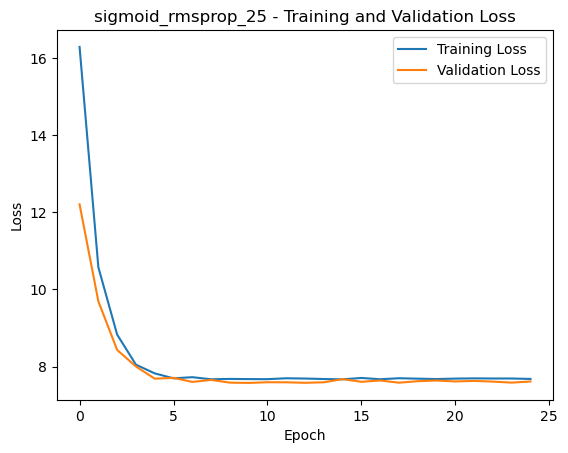

Epoch 1/50


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 18.8640 - val_loss: 12.9618
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.0269 - val_loss: 10.1375
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.6057 - val_loss: 9.0220
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.8597 - val_loss: 8.2609
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0409 - val_loss: 7.9988
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3768 - val_loss: 7.7954
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0277 - val_loss: 7.6703
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7945 - val_loss: 7.6703
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0328 - val_loss: 7.6321
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6117 - val_loss: 7.6237
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3991 - val_loss: 7.5861
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6496 - val_loss: 7.

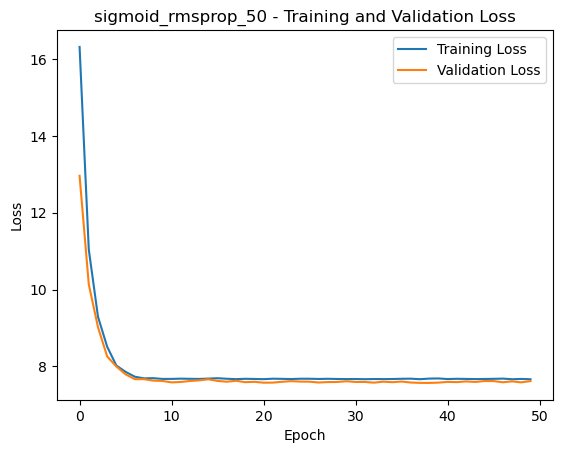

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 14.1135 - val_loss: 10.1200
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.9371 - val_loss: 8.3037
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4698 - val_loss: 7.6864
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0006 - val_loss: 7.6896
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3590 - val_loss: 7.6051
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6660 - val_loss: 7.5770
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6314 - val_loss: 7.6253
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9330 - val_loss: 7.5878
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5834 - val_loss: 7.6220
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0624 - val_loss: 7.6495
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7651 - val_loss: 7.5859
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.4732 - val

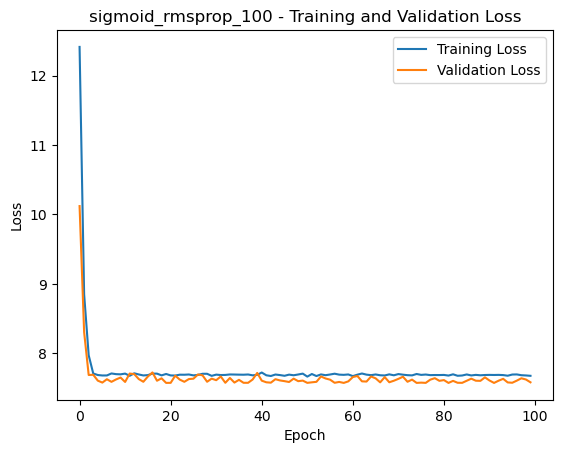

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 14.7043 - val_loss: 10.4690
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.2940 - val_loss: 8.7707
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0380 - val_loss: 7.9542
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2044 - val_loss: 7.7280
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5092 - val_loss: 7.6358
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5911 - val_loss: 7.6084
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7397 - val_loss: 7.6451
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7409 - val_loss: 7.6641
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3591 - val_loss: 7.5822
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0290 - val_loss: 7.5759
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3169 - val_loss: 7.5720
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0786 - val

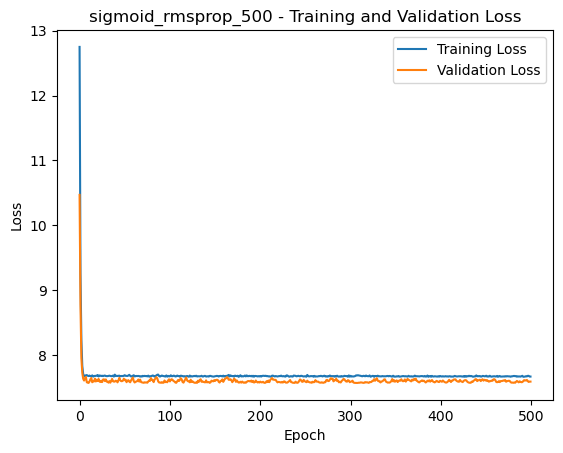

Epoch 1/1000


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 19.4991 - val_loss: 13.6206
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 11.1315 - val_loss: 10.7877
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.5897 - val_loss: 9.3457
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.0496 - val_loss: 8.6999
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3043 - val_loss: 8.3302
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8310 - val_loss: 8.0090
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5731 - val_loss: 7.8599
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9079 - val_loss: 7.7286
Epoch 9/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.6310 - val_loss: 7.7022
Epoch 10/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8623 - val_loss: 7.6585
Epoch 11/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5899 - val_loss: 7.6245
Epoch 12/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss:

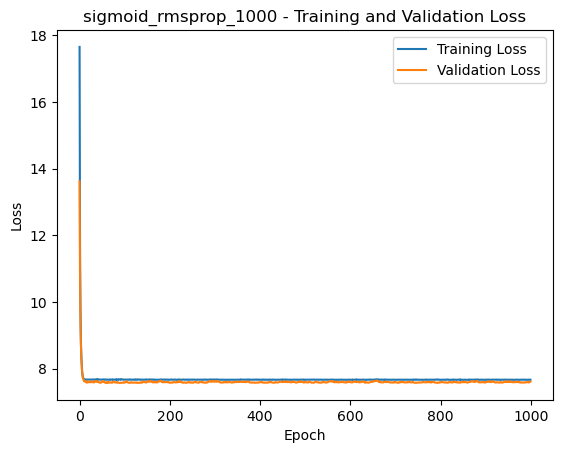

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split  # <-- Add this import
from tensorflow.keras.models import Sequential  # <-- Add this import
from tensorflow.keras.layers import Dense  # <-- Add this import

# Assuming you have run the data preparation code and have `data_cleaned`
# Use the cleaned DataFrame for splitting so the model doesn't get NaNs/infs
train_df, temp_df = train_test_split(data_cleaned, test_size=0.3, random_state=42) # 70% train, 30% temp
val_df, test_df = train_test_split(temp_df, test_size=(1/3), random_state=42) # ~10% test, ~20% validation
 # Define features (X) and target (y)

x_train = train_df[feature_cols]
y_train = train_df[target_col]
x_val = val_df[feature_cols]
y_val = val_df[target_col]
x_test = test_df[feature_cols]
y_test = test_df[target_col]

# Quick sanity checks: ensure there are no NaNs or infs in inputs/targets
def has_invalid(x):
    return np.isnan(x).any() or np.isinf(x).any()

for name, arr in [('x_train', x_train.values), ('y_train', y_train.values), ('x_val', x_val.values), ('y_val', y_val.values), ('x_test', x_test.values), ('y_test', y_test.values)]:
    if has_invalid(arr):
        raise ValueError(f"Invalid values found in {name} (NaN or Inf). Check data_cleaned and preprocessing.")




# activation_functions = ['relu', 'elu', 'selu', 'tanh', 'sigmoid']
activation_functions = ['tanh', 'sigmoid']
# activation_functions = ['tanh']
optimizers = ['adam', 'sgd', 'rmsprop']
# optimizers = ['rmsprop']
# epochs = [15, 50, 100]
epochs = [10, 25, 50, 100, 500, 1000]
models = {}
for activation in activation_functions:
    for optimizer in optimizers:
        for epoch in epochs:
            model_name = f"{activation}_{optimizer}_{epoch}"
            model = Sequential([
                Dense(256, activation=activation, input_shape=(x_train.shape[1],)),  # Input layer
                Dense(128, activation=activation),  # Hidden layer
                Dense(64, activation=activation),  # Hidden layer
                Dense(32, activation=activation),  # Hidden layer
                Dense(1)  # Output layer (regression)
            ])
            model.compile(optimizer=optimizer, loss='mean_squared_error')
            history = model.fit(
                x_train, y_train,
                epochs=epoch,
                validation_data=(x_val, y_val),
                verbose=1
            )
            mse = model.evaluate(x_test, y_test, verbose=0)
            print(f'{model_name}=>Activation: {activation}, Optimizer: {optimizer}, Epochs: {epoch}, Test MSE: {mse}')
            # Store the model and its performance
            # You can use a dictionary or a list to store the models and their performance
            # For example:
            # models[activation + '_' + optimizer + '_' + str(epoch)] = (model, mse)
            models[model_name] = (model, mse)

            # 6. Visualize Training History
            import matplotlib.pyplot as plt
            plt.plot(history.history['loss'], label='Training Loss')
            plt.plot(history.history['val_loss'], label='Validation Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.title(f"{model_name} - Training and Validation Loss")
            plt.legend()
            plt.show()

In [3]:
import numpy as np

if not models:
    print('No models found in `models`. Did the training cell run?')
else:
    def _safe_mse(item):
        """Return a numeric MSE for sorting or +inf when unavailable/NaN."""
        v = item[1]
        try:
            # expect v like (model, mse) or (model, mse, history)
            m = v[1]
            m = float(m)
        except Exception:
            m = float('nan')
        return m if not np.isnan(m) else float('inf')

    sorted_models = sorted(models.items(), key=_safe_mse)
    print("Models sorted by Test MSE (lowest to highest):")
    for name, val in sorted_models:
        try:
            mse_val = val[1]
            mse_str = f"{float(mse_val):.6g}"
        except Exception:
            mse_str = 'N/A'
        print(f"{name}: Test MSE = {mse_str}")

Models sorted by Test MSE (lowest to highest):
tanh_sgd_10: Test MSE = 8.37826
tanh_sgd_1000: Test MSE = 8.38568
sigmoid_adam_10: Test MSE = 8.38815
tanh_rmsprop_10: Test MSE = 8.3927
sigmoid_sgd_1000: Test MSE = 8.4206
tanh_sgd_500: Test MSE = 8.42551
sigmoid_sgd_100: Test MSE = 8.44407
tanh_adam_500: Test MSE = 8.4787
sigmoid_rmsprop_50: Test MSE = 8.49748
sigmoid_sgd_500: Test MSE = 8.50402
sigmoid_rmsprop_1000: Test MSE = 8.50834
sigmoid_rmsprop_25: Test MSE = 8.51136
sigmoid_rmsprop_10: Test MSE = 8.51501
sigmoid_adam_25: Test MSE = 8.52211
tanh_adam_10: Test MSE = 8.52388
tanh_rmsprop_1000: Test MSE = 8.52744
sigmoid_sgd_25: Test MSE = 8.53137
sigmoid_adam_50: Test MSE = 8.53171
sigmoid_adam_100: Test MSE = 8.53542
sigmoid_rmsprop_500: Test MSE = 8.55821
tanh_rmsprop_100: Test MSE = 8.56054
sigmoid_adam_1000: Test MSE = 8.56592
tanh_adam_50: Test MSE = 8.58273
tanh_adam_100: Test MSE = 8.58737
tanh_rmsprop_500: Test MSE = 8.59149
sigmoid_adam_500: Test MSE = 8.59181
tanh_adam_25:

Model: tanh_adam_25, Test MSE: 1.9075324535369873
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step


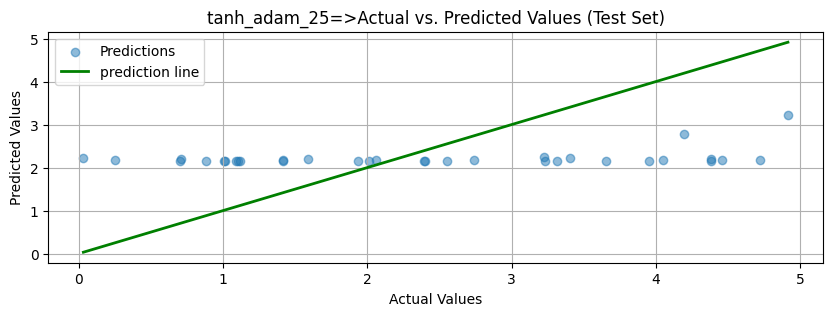

Model: tanh_adam_50, Test MSE: 1.807669997215271
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7519645604c0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step


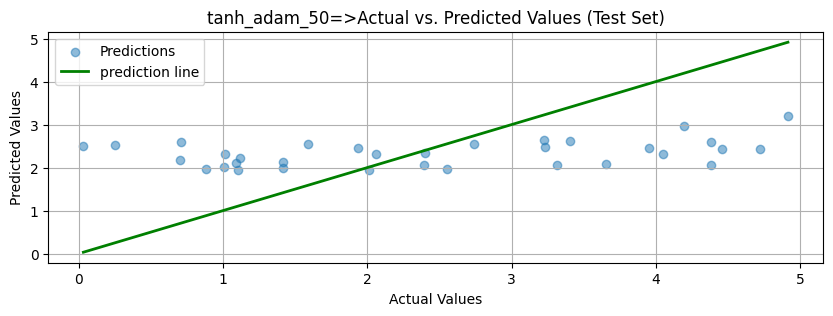

Model: tanh_adam_100, Test MSE: 1.8379379510879517
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 252ms/step


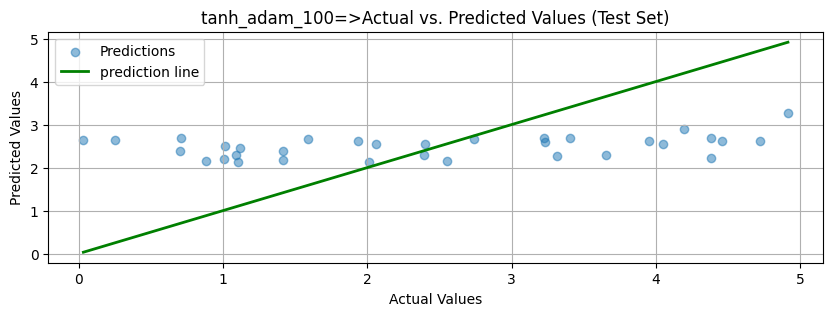

Model: tanh_adam_500, Test MSE: 1.7752279043197632
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 246ms/step


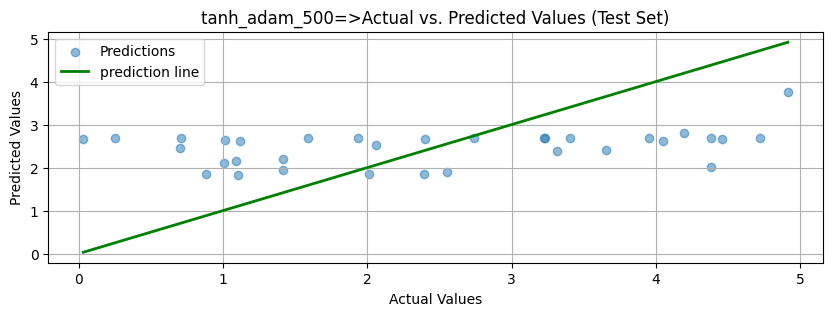

Model: tanh_sgd_25, Test MSE: 2.0236799716949463
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 248ms/step


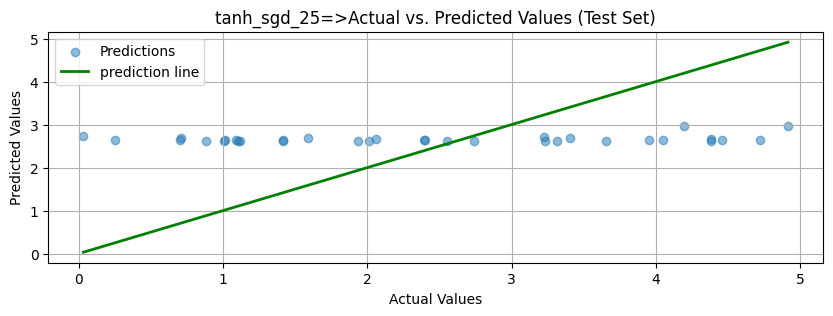

Model: tanh_sgd_50, Test MSE: 2.0155322551727295
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 247ms/step


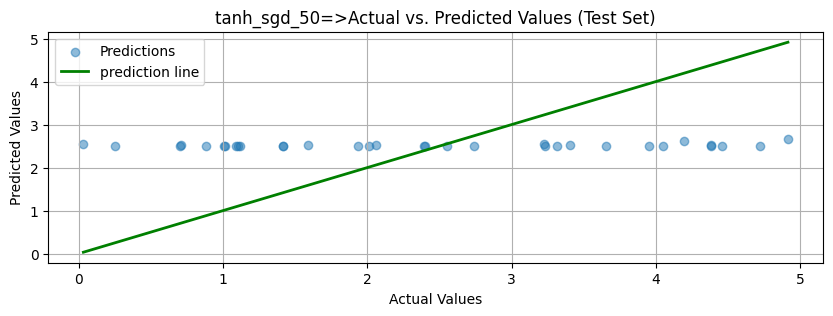

Model: tanh_sgd_100, Test MSE: 2.011216402053833
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 253ms/step


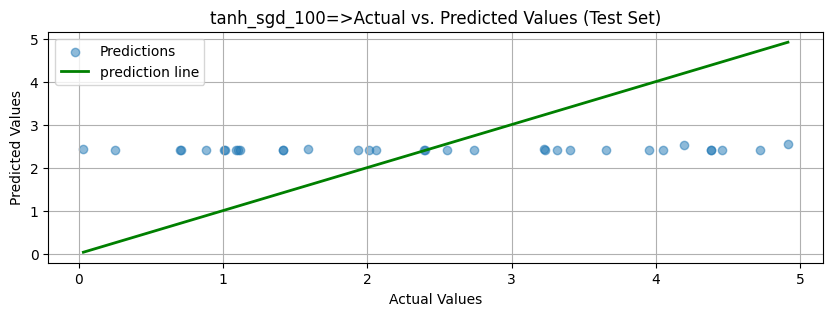

Model: tanh_sgd_500, Test MSE: 2.0599358081817627
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 247ms/step


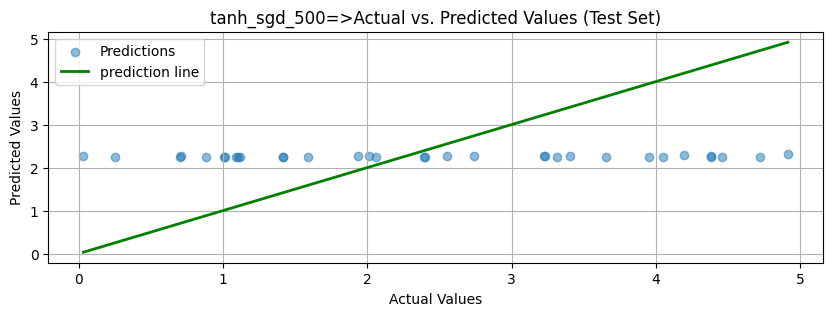

Model: tanh_rmsprop_25, Test MSE: 1.8675950765609741
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 239ms/step


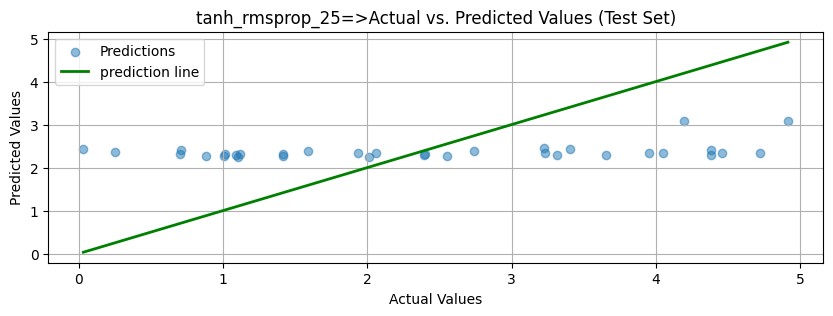

Model: tanh_rmsprop_50, Test MSE: 2.098276138305664
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 250ms/step


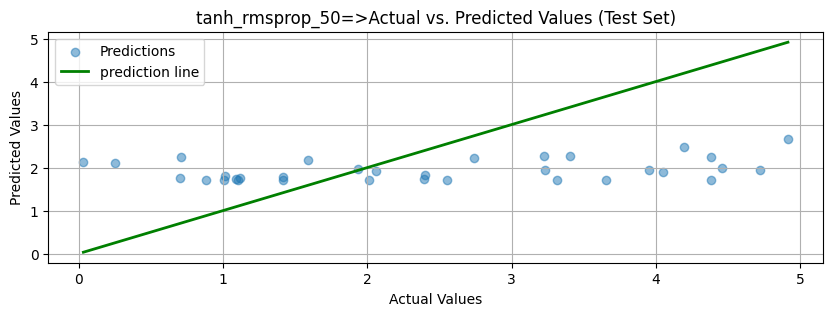

Model: tanh_rmsprop_100, Test MSE: 1.844407558441162
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 248ms/step


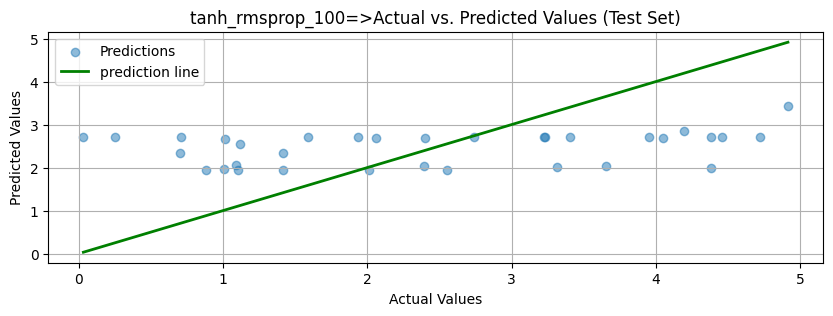

Model: tanh_rmsprop_500, Test MSE: 1.8631747961044312
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 254ms/step


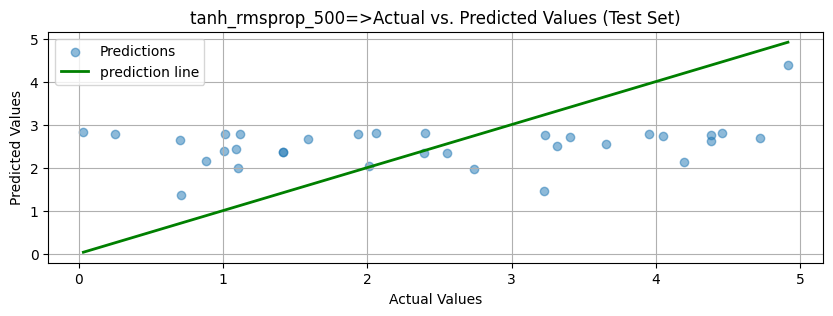

Model: sigmoid_adam_25, Test MSE: 1.9106906652450562
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 244ms/step


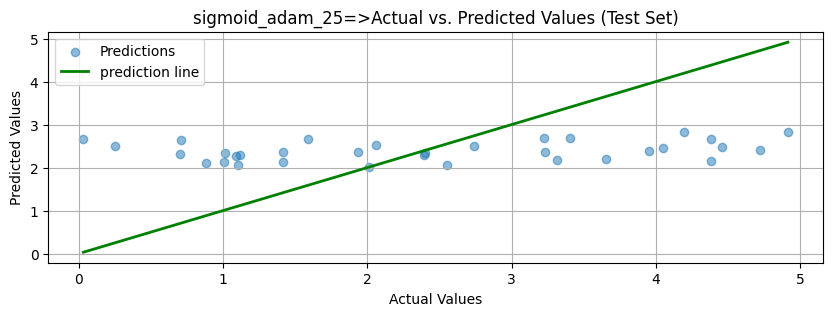

Model: sigmoid_adam_50, Test MSE: 1.901001214981079
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 240ms/step


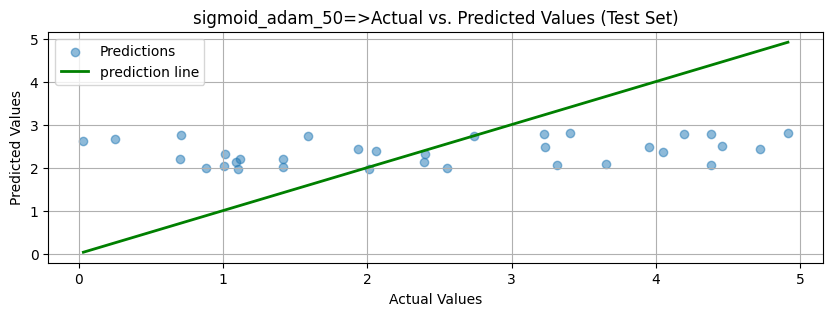

Model: sigmoid_adam_100, Test MSE: 1.8594034910202026
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step


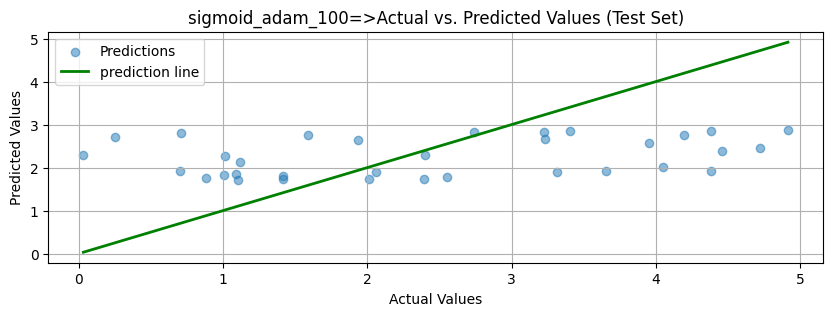

Model: sigmoid_adam_500, Test MSE: 1.792796015739441
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step


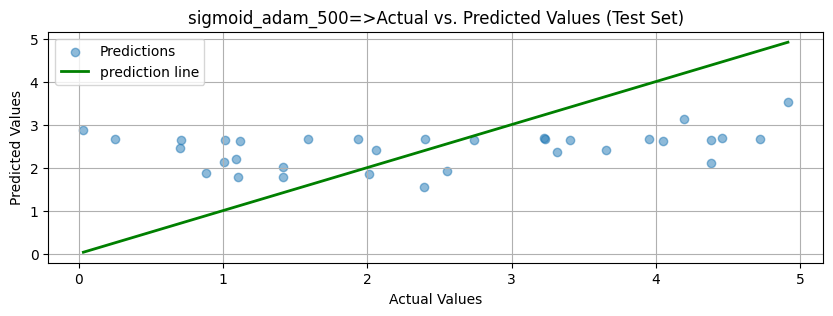

Model: sigmoid_sgd_25, Test MSE: 2.0555672645568848
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 253ms/step


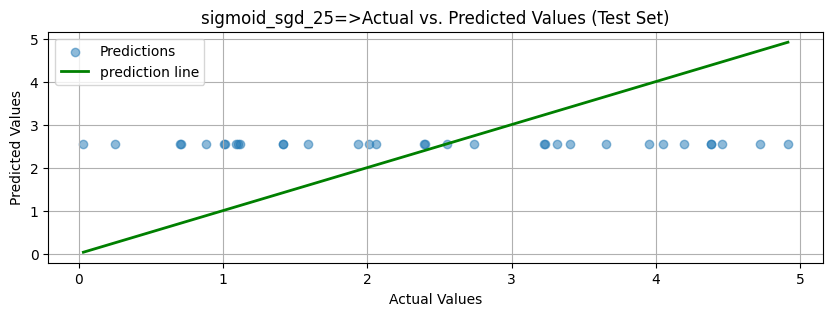

Model: sigmoid_sgd_50, Test MSE: 2.0493431091308594
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 252ms/step


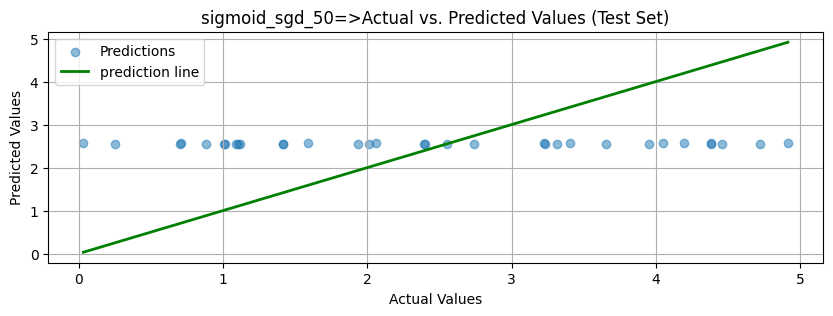

Model: sigmoid_sgd_100, Test MSE: 2.0408244132995605
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 247ms/step


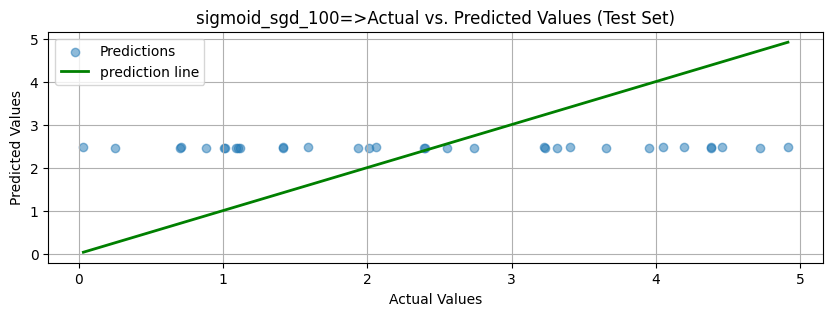

Model: sigmoid_sgd_500, Test MSE: 1.9428356885910034
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 253ms/step


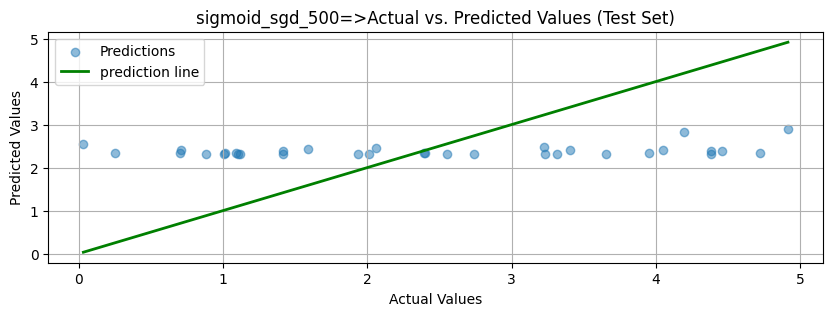

Model: sigmoid_rmsprop_25, Test MSE: 2.100795030593872
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 247ms/step


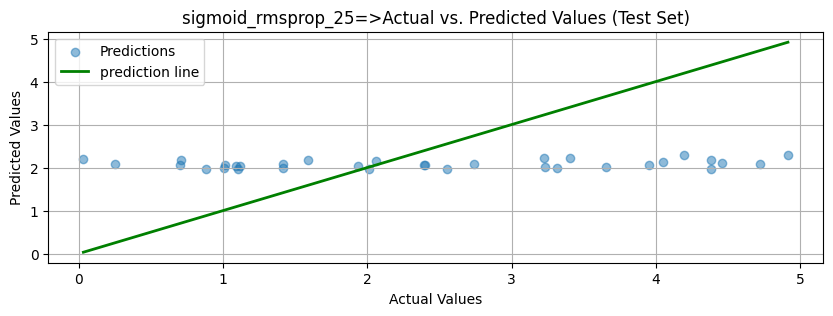

Model: sigmoid_rmsprop_50, Test MSE: 1.9082629680633545
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 248ms/step


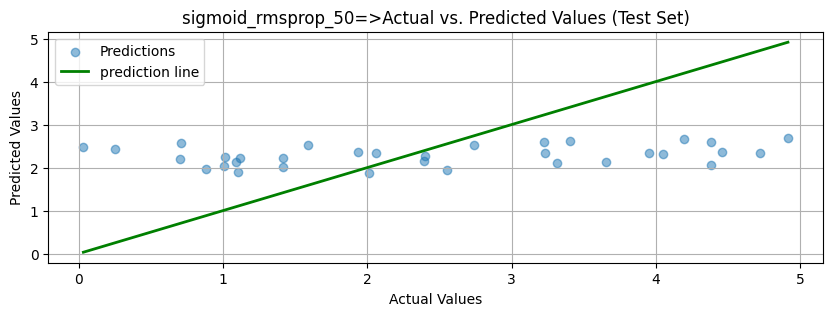

Model: sigmoid_rmsprop_100, Test MSE: 1.833472728729248
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 239ms/step


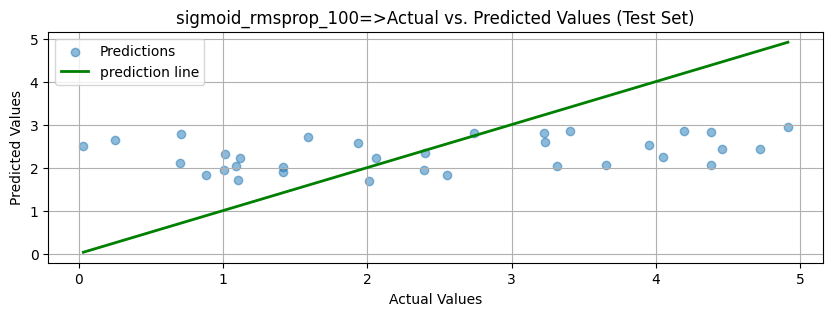

Model: sigmoid_rmsprop_500, Test MSE: 1.8354425430297852
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


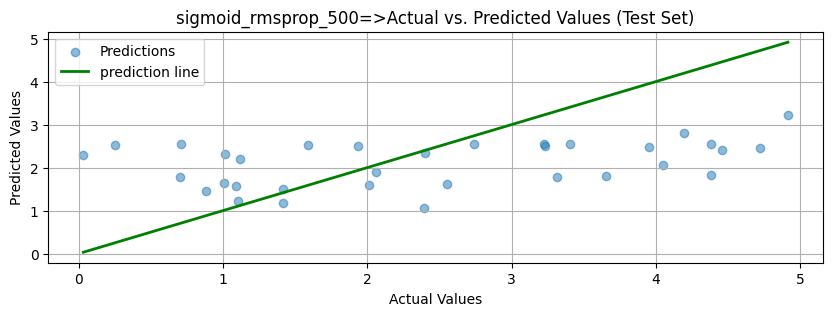

In [7]:
import matplotlib.pyplot as plt
import numpy as np

for model_name, (model, mse) in models.items():
    print(f"Model: {model_name}, Test MSE: {mse}")
    # Assuming you have already trained your model and have x_test
    # Now, let's make predictions on the test set
    if 'model' in locals() and 'x_test' in locals():
        y_pred_test = model.predict(x_test).ravel()  # Flatten to 1D

        # If y_test exists, we can compare predictions to actual values
        if 'y_test' in locals():
            # --- Test Set Visualization ---
            plt.figure(figsize=(10, 3))
            plt.scatter(y_test, y_pred_test, alpha=0.5, label='Predictions')

            # --- Highlight Negative Predictions ---
            negative_predictions_mask = y_pred_test < 0
            if np.any(negative_predictions_mask):
                plt.scatter(
                    y_test[negative_predictions_mask],
                    y_pred_test[negative_predictions_mask],
                    color='red',
                    label='Negative Predictions',
                    s=50,
                    marker='x'
                )
                print("Warning: The model predicted negative values. These might be physically unrealistic depending on what you are predicting.")

            # --- Plot the ideal prediction line ---
            min_val = min(np.min(y_test), np.min(y_test))
            max_val = max(np.max(y_test), np.max(y_test))
            p_min_val = min(np.min(y_pred_test), np.min(y_pred_test))
            p_max_val = max(np.max(y_pred_test), np.max(y_pred_test))
            plt.plot([min_val, max_val], [min_val, max_val], 'g-', lw=2, label='prediction line')

            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title(f'{model_name}=>Actual vs. Predicted Values (Test Set)')
            plt.grid(True)
            plt.legend()
            plt.show()
    else:
        print("Please ensure that the model has been trained ('model' is defined) and you have test data ('x_test' is defined).")